In [ ]:
import pandas as pd


df = pd.read_csv("https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv")

In [ ]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [ ]:
df.shape

(303, 14)

In [ ]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
df.drop(columns=['target'])

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

# 'target' ustunini (bashorat qilinishi kerak bo'lgan qiymatni) o'chirib, faqat kirish xususiyatlarini (X) ajratib olamiz
X = df.drop(columns=['target'])

# Bashorat qilinadigan maqsadli ustunni (y) ajratib olamiz
y = df['target']

# Ma'lumotlarni o'qitish (train) va test (test) to'plamlariga ajratamiz
# test_size=0.2 -> 20% ma'lumot test uchun, 80% esa o'qitish uchun
# stratify=y -> Train va Test to'plamlarida maqsadli sinflar (0 va 1) mutanosibligini saqlaydi
# random_state=42 -> Natijalarning takrorlanuvchanligini ta'minlaydi
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Decision Tree (Qarorlar daraxti) modelini yaratamiz
model = DecisionTreeClassifier()

# Modelni o'qitish to'plami (X_tr, y_tr) yordamida o'qitamiz
model.fit(X_tr, y_tr)

# Modelning aniqlik darajasini (accuracy) train va test to'plamlari uchun hisoblab chiqaramiz
print("O'qitish to'plamidagi aniqlik:", model.score(X_tr, y_tr))
print("Test to'plamidagi aniqlik:", model.score(X_te, y_te))

1.0 0.7049180327868853


In [ ]:
print(export_text(model, feature_names=list(X.columns)))

|--- cp <= 0.50
|   |--- oldpeak <= 0.70
|   |   |--- class: 1
|   |--- oldpeak >  0.70
|   |   |--- class: 0
|--- cp >  0.50
|   |--- thal <= 2.50
|   |   |--- class: 1
|   |--- thal >  2.50
|   |   |--- class: 1



In [ ]:
d = DecisionTreeClassifier(random_state=42)
d.fit(X_tr, y_tr)
print(d.get_depth(), d.get_n_leaves())
print(d.score(X_tr, y_tr), d.score(X_te, y_te))


8 42
1.0 0.7049180327868853


In [ ]:
m = DecisionTreeClassifier(
    max_depth = 3,
    min_samples_leaf = 10,
    random_state=42
)
m.fit(X_tr, y_tr)
print(m.get_depth(), m.get_n_leaves())
print(m.score(X_tr, y_tr), m.score(X_te, y_te))

3 8
0.8429752066115702 0.7540983606557377


In [ ]:
m = DecisionTreeClassifier(
    max_depth = 5 # faqat max_depth ni o'zi bilan hisoblanganda ham 0.78 chiqdi
)
m.fit(X_tr, y_tr)
print(m.get_depth(), m.get_n_leaves())
print(m.score(X_tr, y_tr), m.score(X_te, y_te))

5 21
0.9256198347107438 0.7868852459016393


In [ ]:
m = DecisionTreeClassifier(
    min_samples_leaf = 10 # faqat min_samples_leaf hisoblaganda ham 0.78 chiqdi
)
m.fit(X_tr, y_tr)
print(m.get_depth(), m.get_n_leaves())
print(m.score(X_tr, y_tr), m.score(X_te, y_te))

4 12
0.8512396694214877 0.7868852459016393


In [ ]:
# GridSearchCV moduli orqali eng yaxshi giperparametrlarni qidirish
from sklearn.model_selection import GridSearchCV

# Qidiriladigan giperparametrlar to'plami (grid)
grid = {
    "criterion": ["gini", "entropy"],          # Tarmoqlanish sifatini baholash mezoni
    "max_depth": [2, 3, 4, 5, 6, None],        # Daraxtning maksimal chuqurligi
    "min_samples_leaf": [1, 5, 10, 20],        # Bargda bo'lishi kerak bo'lgan eng kam namunalar soni
    "min_samples_split": [2, 10, 20]           # Tugunni bo'lish uchun kerak bo'lgan eng kam namunalar soni
}

# GridSearch modelini sozlaymiz:
# DecisionTreeClassifier modeliga turli parametrlarni qo'yib tekshiradi
# cv=5 -> 5 ta qatlamli K-Fold Cross Validation qo'llaydi
# n_jobs=-1 -> Barcha protsessor yadrolaridan foydalanib hisoblashni tezlashtiradi
gs = GridSearchCV(DecisionTreeClassifier(random_state=42), grid, cv=5, n_jobs=-1)

# Modelni eng yaxshi kombinatsiyani topish uchun train ma'lumotlarida o'qitamiz
gs.fit(X_tr, y_tr)

# Eng yaxshi natija bergan giperparametrlarni ekranga chiqaramiz
print("Eng yaxshi parametrlar:", gs.best_params_)

# Kross-validatsiyadagi o'rtacha eng yuqori natija (score)
print("Eng yaxshi CV natijasi:", gs.best_score_)

# Topilgan eng yaxshi model yordamida test to'plamidagi aniqlikni tekshiramiz
print("Test to'plamidagi yakuniy aniqlik:", gs.best_estimator_.score(X_te, y_te))

# Izoh: CV (Cross Validation) - faqat train to'plami bilan ishlaydi,
# u hech qachon test bo'lagidan foydalanmaydi (ma'lumotlar sizib chiqishini oldini olish uchun).

{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 2}
0.8099489795918368
0.7540983606557377


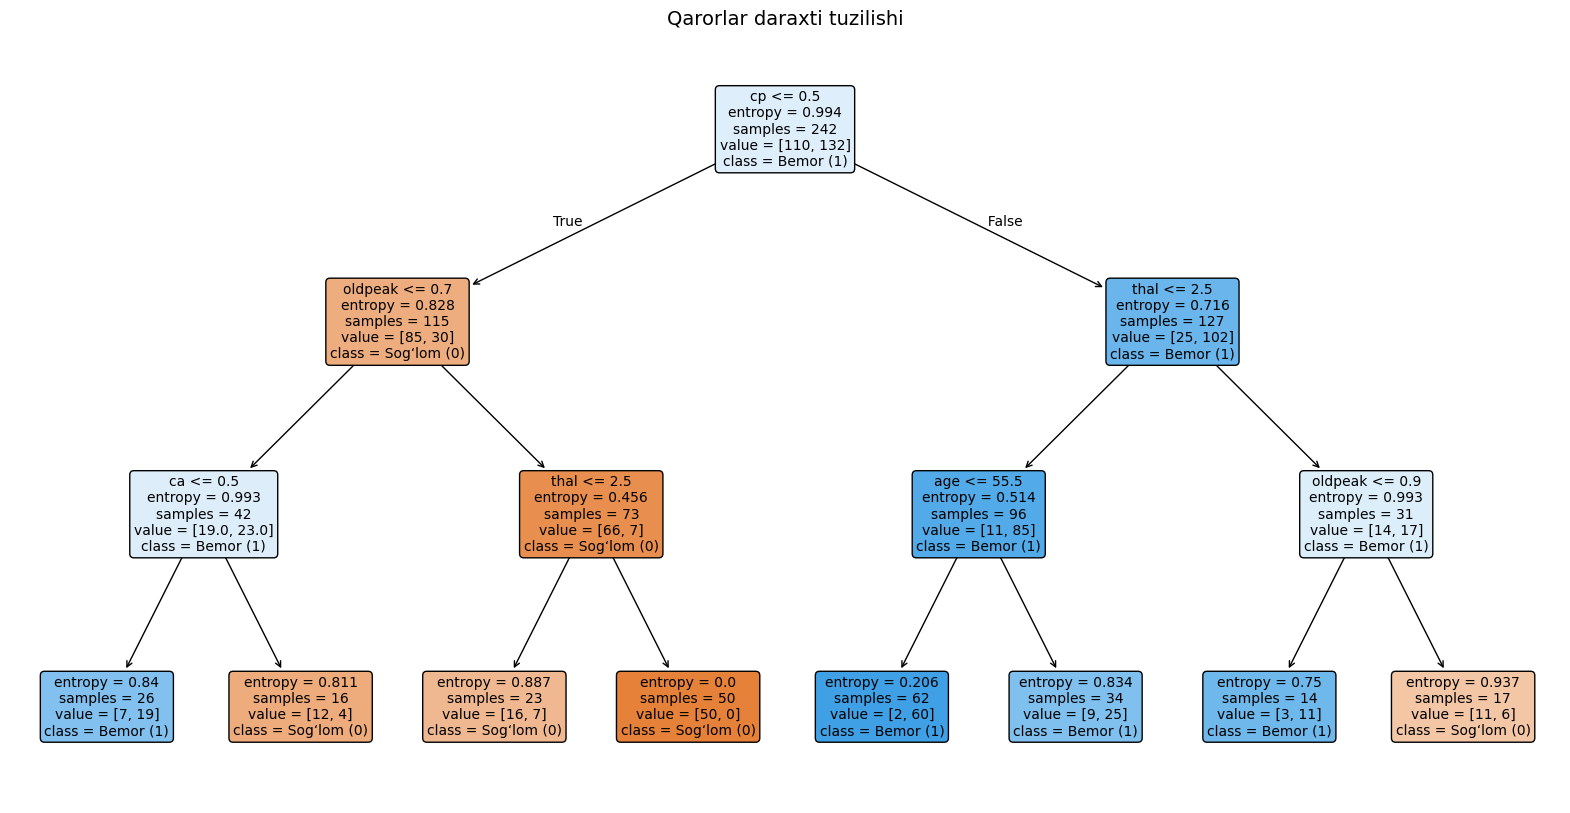

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# 1. Optimal chuqurlikdagi modelni tanlab olamiz
# Eslatma: juda chuqur daraxtlar (masalan, max_depth > 5) rasmda o'qishga noqulay bo'ladi
tree_model = gs.best_estimator_   # yoki avval yaratilgan m modeli

# 2. Rasm o'lchamini belgilaymiz (kattaroq qilish matnlar bir-biriga tushib ketmasligini ta'minlaydi)
plt.figure(figsize=(20, 10))

# 3. Daraxtni chizamiz
plot_tree(
    tree_model,
    feature_names=list(X.columns),          # Ustun nomlari
    class_names=['Sog‘lom (0)', 'Bemor (1)'], # Target sinflari nomlari
    filled=True,                            # Tugunlarni sinf bo'yicha ranglash (gini/entropy darajasiga qarab)
    rounded=True,                           # Burchaklarni yumaloq shaklga keltirish
    fontsize=10                             # Shrift o'lchami
)

# 4. Chizmani ko'rsatamiz va fayl sifatida saqlaymiz
plt.title("Qarorlar daraxti tuzilishi", fontsize=14)
plt.savefig("decision_tree.png", dpi=300, bbox_inches='tight') # rasmni kompyuterga yuklab olish
plt.show()